# Olist E-Commerce: Charts + Modeling
**Question:** Why do customers give bad reviews, and how much does late delivery matter?

- Part A: Charts (EDA)
- Part B: Logistic Regression: predict a **bad review** (1-2 stars), yes or no
- Part C: Linear Regression: predict the review **score** (1 to 5)

*Run this notebook from the `olist_streamlit` folder (next to the `data` folder).*

In [1]:
from pathlib import Path

import matplotlib
import numpy as np
import pandas as pd

SHOW = True                        # charts show inside the notebook
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, mean_absolute_error,
                             mean_squared_error, precision_score, r2_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

TEAL, AMBER, RED, GREY = "#348E90", "#D98E1F", "#B84A3E", "#6B6B6B"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "axes.titleweight": "bold"})

HERE = Path.cwd()
DATA = HERE / "data" if (HERE / "data").exists() else HERE
CHARTS = HERE / "charts"
CHARTS.mkdir(exist_ok=True)


def save(name):
    plt.tight_layout()
    path = CHARTS / name
    plt.savefig(path, bbox_inches="tight")
    print(f"   saved chart -> charts/{name}")
    if SHOW:
        plt.show()
    plt.close()

## 1. LOAD DATA

In [2]:
print("\n[1] Loading data...")
o = pd.read_parquet(DATA / "orders.parquet")
oi = pd.read_parquet(DATA / "order_items.parquet")
p = pd.read_parquet(DATA / "payments.parquet")

for c in ["is_sales_order", "valid_delivery", "is_late", "review_score", "delivery_days",
          "estimated_days", "delay_days", "item_sales"]:
    o[c] = o[c].astype("float64")
for c in ["price", "freight_value"]:
    oi[c] = oi[c].astype("float64")
for c in ["payment_value", "payment_installments"]:
    p[c] = p[c].astype("float64")
o["month"] = o["purchase_date"].dt.to_period("M").astype(str)

# Build extra order-level columns from the items and payments tables
per_order_items = oi.groupby("order_id").agg(
    freight=("freight_value", "sum"),          # total shipping cost of the order
    n_items=("price", "size"),                 # number of items in the order
    n_sellers=("seller_id", "nunique"),        # number of different sellers
)
per_order_pay = p.groupby("order_id").agg(max_installments=("payment_installments", "max"))
main_type = (p.sort_values("payment_value", ascending=False)
               .drop_duplicates("order_id")
               .set_index("order_id")["payment_type"].rename("main_payment_type"))
o = (o.merge(per_order_items, on="order_id", how="left")
       .merge(per_order_pay, on="order_id", how="left")
       .merge(main_type, on="order_id", how="left"))

print(f"   orders: {len(o):,} | order items: {len(oi):,} | payments: {len(p):,}")


[1] Loading data...


   orders: 99,441 | order items: 112,650 | payments: 103,886


## PART A - CHARTS

In [3]:
print("\n[2] Part A: making charts...")
sales = o[o["is_sales_order"] == 1]
valid = o[o["valid_delivery"] == 1]


[2] Part A: making charts...


**Chart 1: review score distribution**

   saved chart -> charts/01_review_distribution.png


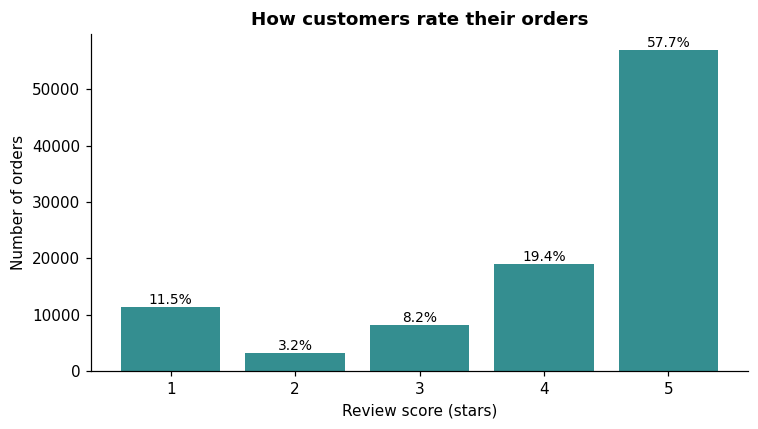

In [4]:
plt.figure(figsize=(7, 4))
t = o["review_score"].round().value_counts().sort_index()
bars = plt.bar(t.index.astype(int).astype(str), t.values, color=TEAL)
for b, v in zip(bars, t.values):
    plt.text(b.get_x() + b.get_width() / 2, v, f"{v / t.sum():.1%}", ha="center", va="bottom", fontsize=9)
plt.title("How customers rate their orders")
plt.xlabel("Review score (stars)")
plt.ylabel("Number of orders")
save("01_review_distribution.png")

**Chart 2: monthly orders (bars) and item sales (line)**

   saved chart -> charts/02_monthly_orders_sales.png


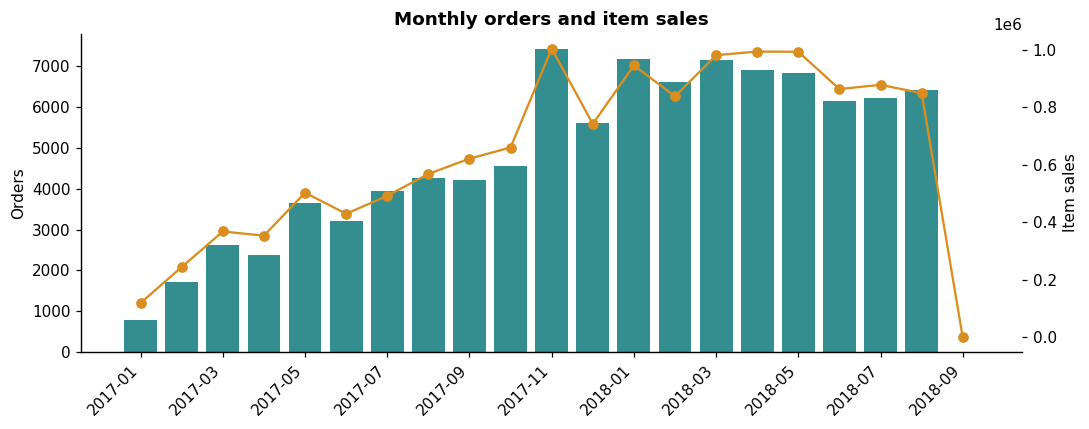

In [5]:
m = sales.groupby("month").agg(orders=("order_id", "nunique"), sales=("item_sales", "sum"))
m = m[m.index >= "2017-01"]                   # 2016 has very few orders, so skip it
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(m.index, m["orders"], color=TEAL, label="Orders")
ax.set_ylabel("Orders")
ax.set_xticks(range(0, len(m), 2))
ax.set_xticklabels(m.index[::2], rotation=45, ha="right")
ax2 = ax.twinx()
ax2.plot(m.index, m["sales"], color=AMBER, marker="o", label="Item sales")
ax2.set_ylabel("Item sales")
ax2.spines["top"].set_visible(False)
ax.set_title("Monthly orders and item sales")
save("02_monthly_orders_sales.png")

**Chart 3: top 10 categories by sales**

   saved chart -> charts/03_top_categories.png


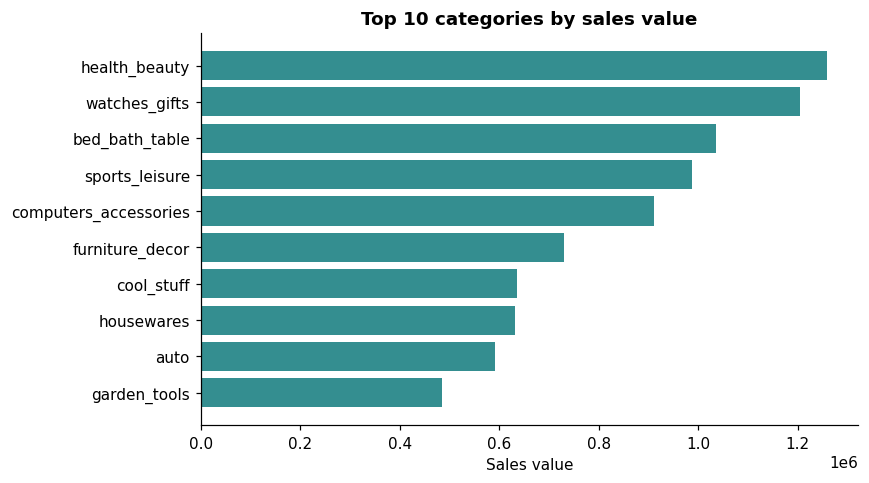

In [6]:
t = oi.groupby("category")["price"].sum().nlargest(10).iloc[::-1]
plt.figure(figsize=(8, 4.5))
plt.barh(t.index, t.values, color=TEAL)
plt.title("Top 10 categories by sales value")
plt.xlabel("Sales value")
save("03_top_categories.png")

**Chart 4: average delivery days by state**

   saved chart -> charts/04_delivery_days_by_state.png

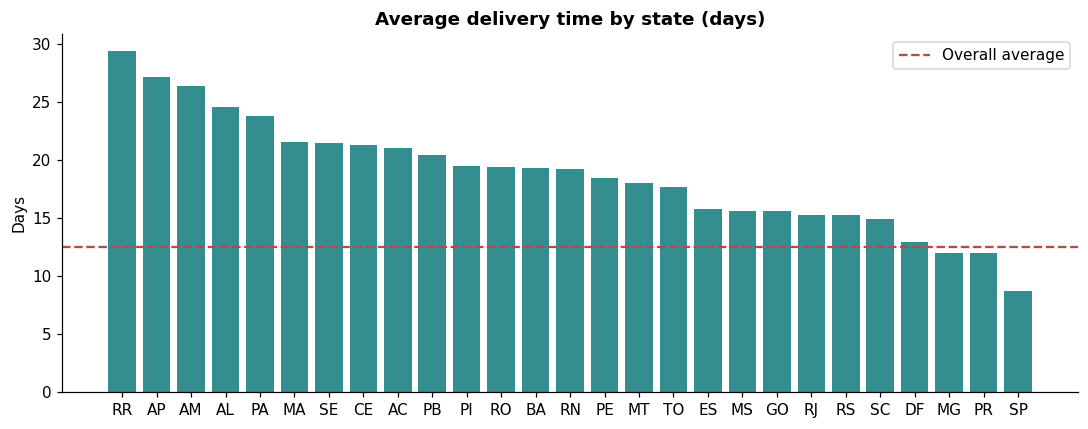

In [7]:
t = valid.groupby("customer_state")["delivery_days"].mean().sort_values(ascending=False)
plt.figure(figsize=(10, 4))
plt.bar(t.index, t.values, color=TEAL)
plt.axhline(valid["delivery_days"].mean(), color=RED, ls="--", label="Overall average")
plt.title("Average delivery time by state (days)")
plt.ylabel("Days")
plt.legend()
save("04_delivery_days_by_state.png")

**Chart 5: late delivery rate by month**

   saved chart -> charts/05_late_rate_by_month.png


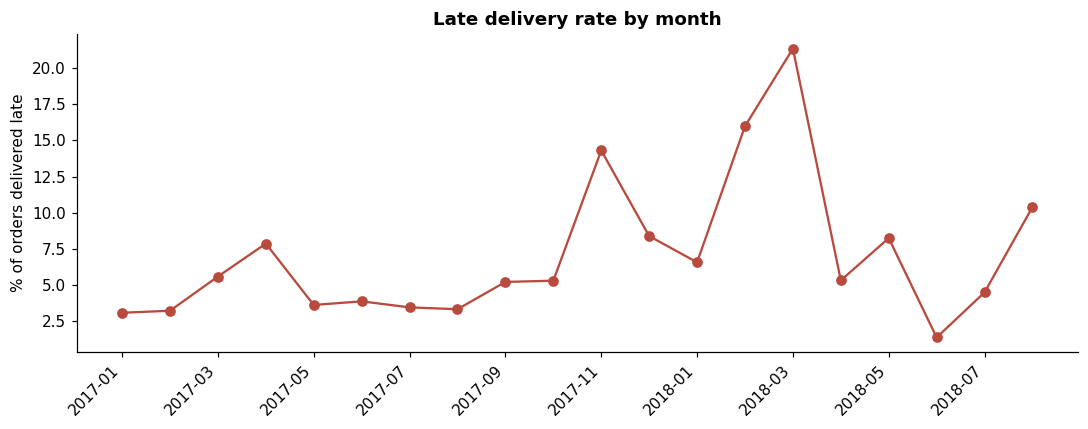

In [8]:
late = o[o["is_late"] == 1].groupby("month").size()
v = valid.groupby("month").size()
t = (late.reindex(v.index).fillna(0) / v)
t = t[t.index >= "2017-01"]
plt.figure(figsize=(10, 4))
plt.plot(t.index, t.values * 100, color=RED, marker="o")
plt.xticks(range(0, len(t), 2), t.index[::2], rotation=45, ha="right")
plt.title("Late delivery rate by month")
plt.ylabel("% of orders delivered late")
save("05_late_rate_by_month.png")

**Chart 6: average review score by delay bucket**

   saved chart -> charts/06_review_by_delay_bucket.png


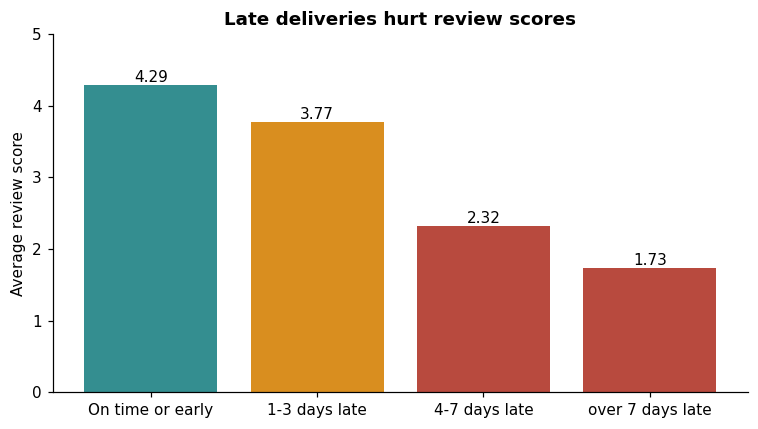

In [9]:
t = o[o["Delay Bucket"] != "n/a"].groupby("Delay Bucket")["review_score"].mean().sort_index()
plt.figure(figsize=(7, 4))
bars = plt.bar([s[2:] for s in t.index], t.values, color=[TEAL, AMBER, RED, RED])
for b, v in zip(bars, t.values):
    plt.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom")
plt.title("Late deliveries hurt review scores")
plt.ylabel("Average review score")
plt.ylim(0, 5)
save("06_review_by_delay_bucket.png")

**Chart 7: payment method share**

   saved chart -> charts/07_payment_mix.png


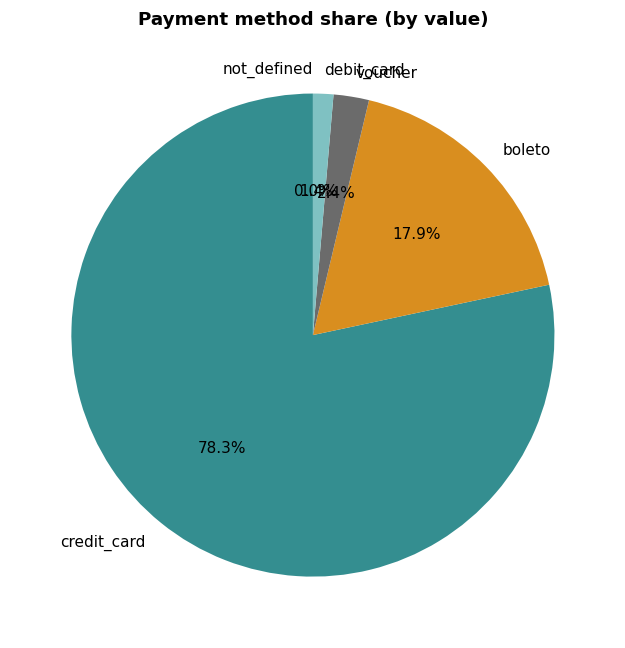

In [10]:
t = p.groupby("payment_type")["payment_value"].sum().sort_values(ascending=False)
plt.figure(figsize=(6, 6))
plt.pie(t.values, labels=t.index, autopct="%1.1f%%", startangle=90,
        colors=[TEAL, AMBER, GREY, "#7FC1C2", RED])
plt.title("Payment method share (by value)")
save("07_payment_mix.png")

**Chart 8: correlation heatmap**

   saved chart -> charts/08_correlation_heatmap.png


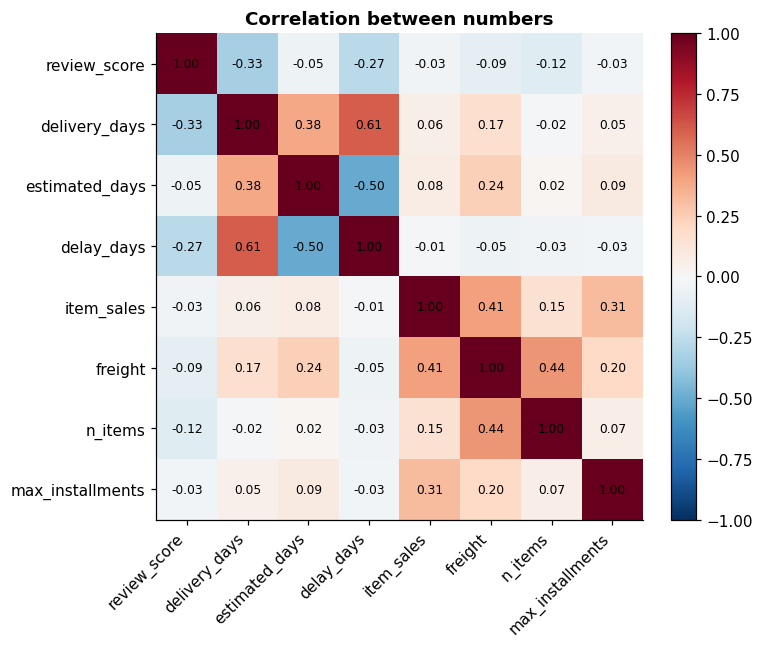

In [11]:
cols = ["review_score", "delivery_days", "estimated_days", "delay_days", "item_sales",
        "freight", "n_items", "max_installments"]
corr = valid[cols].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols)))
ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, fraction=0.046)
ax.set_title("Correlation between numbers")
save("08_correlation_heatmap.png")

## 3. PREPARE DATA FOR MODELS

In [12]:
print("\n[3] Preparing data for models...")
# Only delivered, valid sales orders that have a review.
d = o[(o["is_sales_order"] == 1) & (o["valid_delivery"] == 1) & o["review_score"].notna()].copy()
d["bad_review"] = (d["review_score"] <= 2).astype(int)          # 1 = bad review
d["same_state"] = (d["customer_state"] == d["first_seller_state"]).astype(int)
d["main_payment_type"] = d["main_payment_type"].fillna("unknown")

NUM = ["delivery_days", "estimated_days", "is_late", "item_sales", "freight",
       "n_items", "n_sellers", "max_installments", "same_state"]
CAT = ["main_payment_type"]
d = d.dropna(subset=NUM + CAT)

print(f"   rows used: {len(d):,}")
print(f"   bad reviews (1-2 stars): {d['bad_review'].mean():.1%}")
# delay_days is left out on purpose: it equals delivery_days minus estimated_days,
# so using all three would confuse the model.

pre = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), CAT),
])
X_raw = d[NUM + CAT]
y_cls = d["bad_review"]
y_reg = d["review_score"]

Xtr_raw, Xte_raw, ytr_c, yte_c, ytr_r, yte_r = train_test_split(
    X_raw, y_cls, y_reg, test_size=0.2, random_state=42, stratify=y_cls)
Xtr = pre.fit_transform(Xtr_raw)
Xte = pre.transform(Xte_raw)
names = [n.split("__")[1] for n in pre.get_feature_names_out()]
print(f"   training rows: {len(Xtr):,} | testing rows: {len(Xte):,}")


[3] Preparing data for models...


   rows used: 95,800
   bad reviews (1-2 stars): 12.8%
   training rows: 76,640 | testing rows: 19,160


## PART B - LOGISTIC REGRESSION (predict bad review: yes / no)

In [13]:
print("\n[4] Part B: Logistic Regression (bad review = 1-2 stars)")
logit = LogisticRegression(max_iter=1000, class_weight="balanced")
logit.fit(Xtr, ytr_c)
prob = logit.predict_proba(Xte)[:, 1]
pred = (prob >= 0.5).astype(int)

acc = accuracy_score(yte_c, pred)
prec = precision_score(yte_c, pred)
rec = recall_score(yte_c, pred)
auc = roc_auc_score(yte_c, prob)
baseline = 1 - yte_c.mean()
print(f"   Accuracy  : {acc:.1%}   (always guessing 'good review' would give {baseline:.1%})")
print(f"   Precision : {prec:.1%}   (of orders we flag as bad, this many really are bad)")
print(f"   Recall    : {rec:.1%}   (of all really bad reviews, we catch this many)")
print(f"   ROC-AUC   : {auc:.3f}   (0.5 = random guess, 1.0 = perfect)")


[4] Part B: Logistic Regression (bad review = 1-2 stars)


   Accuracy  : 82.9%   (always guessing 'good review' would give 87.2%)
   Precision : 37.7%   (of orders we flag as bad, this many really are bad)
   Recall    : 52.4%   (of all really bad reviews, we catch this many)
   ROC-AUC   : 0.742   (0.5 = random guess, 1.0 = perfect)


**Chart 9: confusion matrix**

   saved chart -> charts/09_logit_confusion_matrix.png


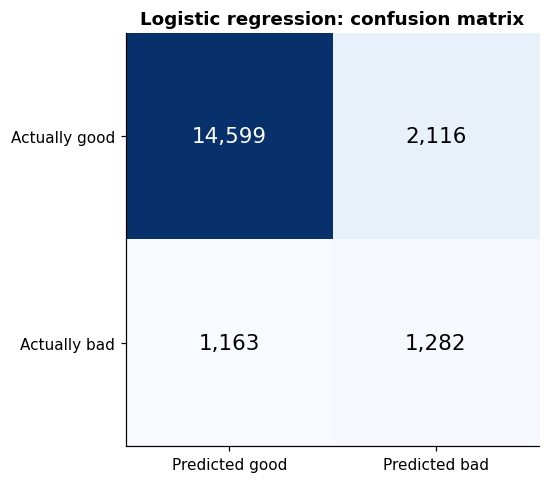

In [14]:
cm = confusion_matrix(yte_c, pred)
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Predicted good", "Predicted bad"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["Actually good", "Actually bad"])
ax.set_title("Logistic regression: confusion matrix")
save("09_logit_confusion_matrix.png")

**Chart 10: ROC curve**

   saved chart -> charts/10_logit_roc_curve.png


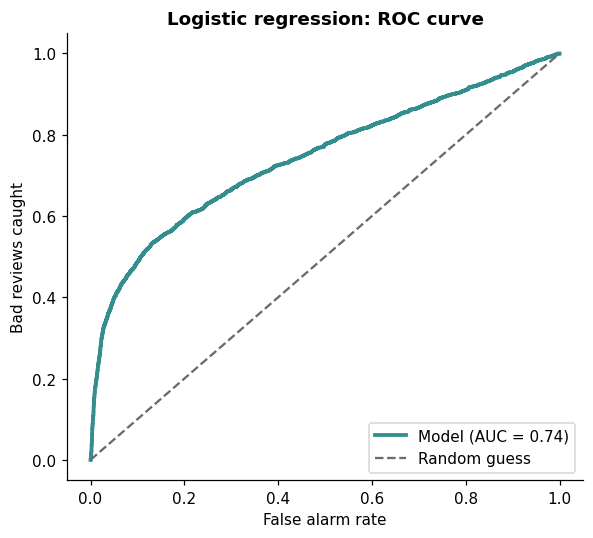

In [15]:
fpr, tpr, _ = roc_curve(yte_c, prob)
plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, color=TEAL, lw=2.5, label=f"Model (AUC = {auc:.2f})")
plt.plot([0, 1], [0, 1], color=GREY, ls="--", label="Random guess")
plt.xlabel("False alarm rate")
plt.ylabel("Bad reviews caught")
plt.title("Logistic regression: ROC curve")
plt.legend(loc="lower right")
save("10_logit_roc_curve.png")

**Chart 11: odds ratios**

   saved chart -> charts/11_logit_odds_ratios.png


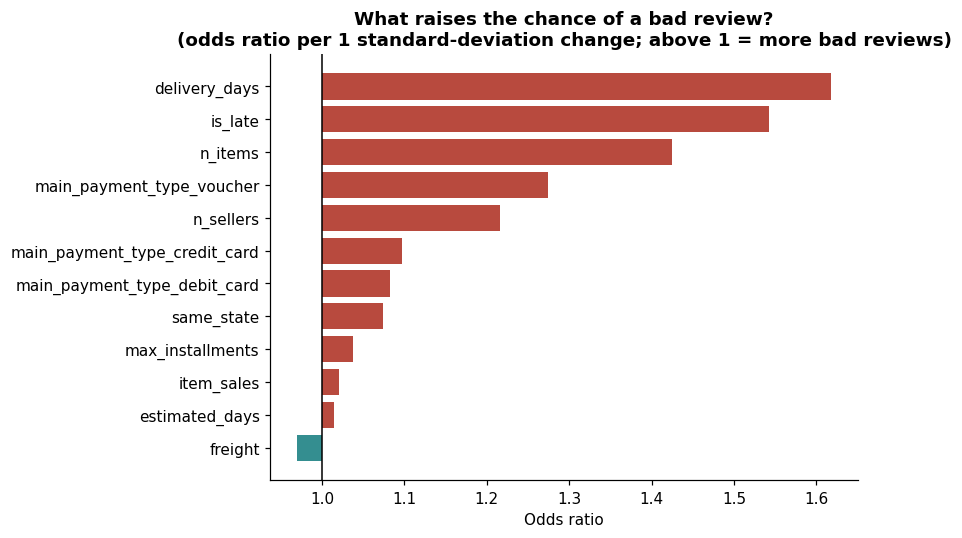


   Odds ratios (above 1 = raises the chance of a bad review):
     delivery_days                  1.62
     is_late                        1.54
     n_items                        1.42
     main_payment_type_voucher      1.27
     n_sellers                      1.22
     main_payment_type_credit_card   1.10
     main_payment_type_debit_card   1.08
     same_state                     1.07
     max_installments               1.04
     item_sales                     1.02
     estimated_days                 1.01
     freight                        0.97


In [16]:
odds = pd.Series(np.exp(logit.coef_[0]), index=names).sort_values()
plt.figure(figsize=(8, 5))
plt.barh(odds.index, odds.values - 1, left=1,
         color=[RED if v > 1 else TEAL for v in odds.values])
plt.axvline(1, color="black", lw=1)
plt.title("What raises the chance of a bad review?\n(odds ratio per 1 standard-deviation change; above 1 = more bad reviews)")
plt.xlabel("Odds ratio")
save("11_logit_odds_ratios.png")

print("\n   Odds ratios (above 1 = raises the chance of a bad review):")
for k, v in odds.sort_values(ascending=False).items():
    print(f"     {k:28s} {v:6.2f}")

## PART C - LINEAR REGRESSION (predict review score 1 to 5)

In [17]:
print("\n[5] Part C: Linear Regression (predict the review score)")
lin = LinearRegression().fit(Xtr, ytr_r)
pred_r = np.clip(lin.predict(Xte), 1, 5)
r2 = r2_score(yte_r, pred_r)
rmse = np.sqrt(mean_squared_error(yte_r, pred_r))
mae = mean_absolute_error(yte_r, pred_r)
dumb_rmse = np.sqrt(mean_squared_error(yte_r, np.full(len(yte_r), ytr_r.mean())))
print(f"   R-squared : {r2:.3f}   (share of the review-score ups and downs the model explains)")
print(f"   RMSE      : {rmse:.3f} stars   (always guessing the average gives {dumb_rmse:.3f})")
print(f"   MAE       : {mae:.3f} stars   (typical miss)")

# p-values with statsmodels (shows which features really matter)
ols = sm.OLS(ytr_r.values, sm.add_constant(pd.DataFrame(Xtr, columns=names))).fit()
res = pd.DataFrame({"coefficient": ols.params, "p_value": ols.pvalues}).drop("const")
res["significant"] = np.where(res["p_value"] < 0.05, "yes", "no")
print("\n   Coefficients (stars gained or lost per 1 standard-deviation change):")
print(res.sort_values("coefficient").round(4).to_string())


[5] Part C: Linear Regression (predict the review score)
   R-squared : 0.188   (share of the review-score ups and downs the model explains)
   RMSE      : 1.156 stars   (always guessing the average gives 1.283)
   MAE       : 0.892 stars   (typical miss)



   Coefficients (stars gained or lost per 1 standard-deviation change):
                               coefficient  p_value significant
is_late                            -0.3212   0.0000         yes
delivery_days                      -0.2624   0.0000         yes
n_items                            -0.1340   0.0000         yes
n_sellers                          -0.1300   0.0000         yes
main_payment_type_voucher          -0.0911   0.0004         yes
main_payment_type_credit_card      -0.0487   0.0000         yes
same_state                         -0.0261   0.0000         yes
max_installments                   -0.0036   0.4614          no
item_sales                         -0.0016   0.7357          no
estimated_days                      0.0051   0.3479          no
main_payment_type_debit_card        0.0062   0.8604          no
freight                             0.0079   0.1361          no


**Chart 12: coefficients**

   saved chart -> charts/12_linear_coefficients.png


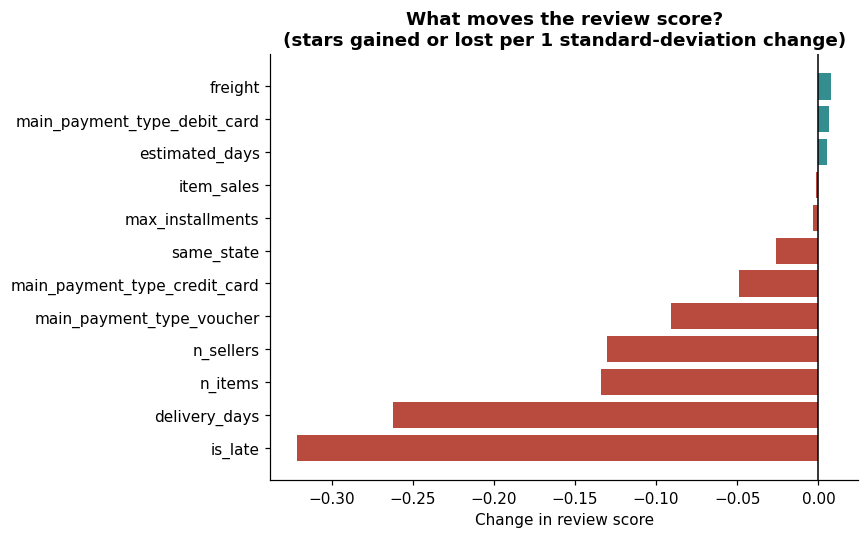

In [18]:
r = res.sort_values("coefficient")
plt.figure(figsize=(8, 5))
plt.barh(r.index, r["coefficient"], color=[TEAL if c > 0 else RED for c in r["coefficient"]])
plt.axvline(0, color="black", lw=1)
plt.title("What moves the review score?\n(stars gained or lost per 1 standard-deviation change)")
plt.xlabel("Change in review score")
save("12_linear_coefficients.png")

**Chart 13: actual vs predicted (average per predicted bucket)**

   saved chart -> charts/13_linear_actual_vs_predicted.png


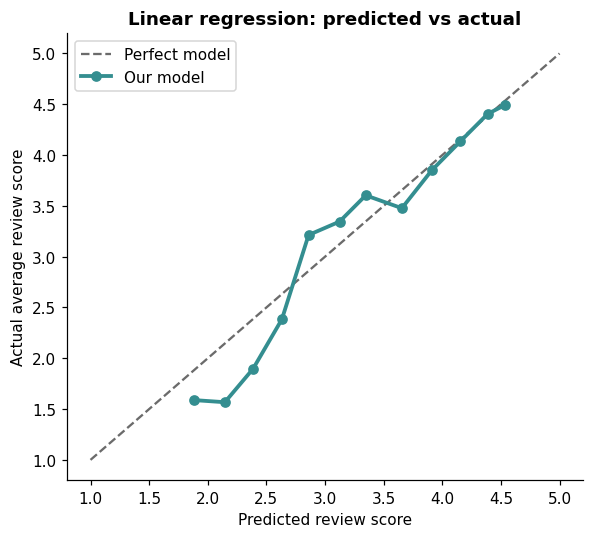

In [19]:
cmp = pd.DataFrame({"pred": pred_r, "actual": yte_r.values})
cmp["bucket"] = pd.cut(cmp["pred"], bins=np.arange(1, 5.01, 0.25))
g = cmp.groupby("bucket", observed=True).agg(pred=("pred", "mean"), actual=("actual", "mean"),
                                             n=("actual", "size"))
g = g[g["n"] >= 30]
plt.figure(figsize=(5.5, 5))
plt.plot([1, 5], [1, 5], color=GREY, ls="--", label="Perfect model")
plt.plot(g["pred"], g["actual"], color=TEAL, marker="o", lw=2.5, label="Our model")
plt.xlabel("Predicted review score")
plt.ylabel("Actual average review score")
plt.title("Linear regression: predicted vs actual")
plt.legend()
save("13_linear_actual_vs_predicted.png")

**Chart 14: residuals**

   saved chart -> charts/14_linear_residuals.png


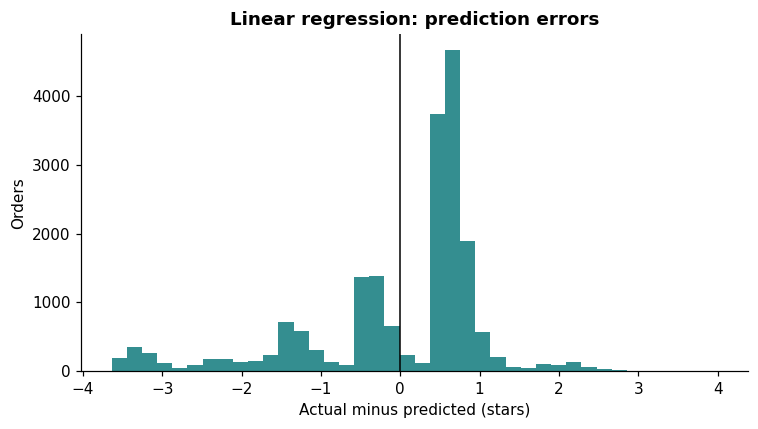

In [20]:
plt.figure(figsize=(7, 4))
plt.hist(yte_r.values - pred_r, bins=40, color=TEAL)
plt.axvline(0, color="black", lw=1)
plt.title("Linear regression: prediction errors")
plt.xlabel("Actual minus predicted (stars)")
plt.ylabel("Orders")
save("14_linear_residuals.png")

## 6. PLAIN-ENGLISH SUMMARY

In [21]:
late_mean = d.loc[d["is_late"] == 1, "review_score"].mean()
ontime_mean = d.loc[d["is_late"] == 0, "review_score"].mean()
late_bad = d.loc[d["is_late"] == 1, "bad_review"].mean()
ontime_bad = d.loc[d["is_late"] == 0, "bad_review"].mean()
print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)
print(f"- Late orders get {late_mean:.2f} stars on average. On-time orders get {ontime_mean:.2f}.")
print(f"- {late_bad:.0%} of late orders get a bad review. For on-time orders it is {ontime_bad:.0%}.")
print(f"- Logistic regression: ROC-AUC {auc:.2f}, recall {rec:.0%}, precision {prec:.0%}.")
print(f"- Linear regression:   R-squared {r2:.2f}, typical miss {mae:.2f} stars.")
print("- These models show links, not proof of cause. Late delivery goes together")
print("  with bad reviews, but other things (product quality, wrong item) are not in this data.")
print(f"\nDone. {len(list(CHARTS.glob('*.png')))} charts are in: {CHARTS}")


SUMMARY
- Late orders get 2.57 stars on average. On-time orders get 4.29.
- 54% of late orders get a bad review. For on-time orders it is 9%.
- Logistic regression: ROC-AUC 0.74, recall 52%, precision 38%.
- Linear regression:   R-squared 0.19, typical miss 0.89 stars.
- These models show links, not proof of cause. Late delivery goes together
  with bad reviews, but other things (product quality, wrong item) are not in this data.

Done. 14 charts are in: /home/claude/olist_streamlit/charts
